In [237]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib import patches
from cmath import rect
%matplotlib inline

Nitrogen

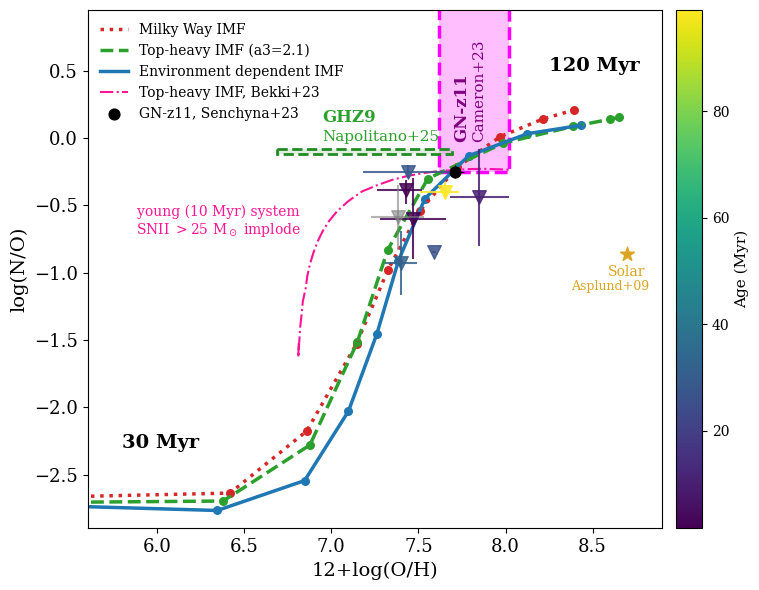

In [ ]:
def load_file_paths(base_dir):
    file_paths = []
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file == "chemical_and_SN_evolution.txt":
                file_paths.append(os.path.join(root, file))
    return file_paths

def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

def recalculate(logNO, logOH): # Recalculate logNO and logOH
    logNO = [i - 0.86 for i in logNO]
    logOH = [i + 8.696 for i in logOH]
    return logNO, logOH

def fit(logOH, logNO): # Fit a polynomial to the data
    coefficients = np.polyfit(logOH, logNO, deg=6)
    polynomial = np.poly1d(coefficients)
    smooth_logOH = np.linspace(min(logOH[6:]), max(logOH[6:]), 500)
    smooth_logNO = polynomial(smooth_logOH)
    return smooth_logOH, smooth_logNO

def prepare_data(file_paths):
    for path in file_paths:
        data = load_data_with_names(path)
        logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
        FeH, MgH, OH = data['Gas [Fe/H]:'], data['Gas [Mg/H]:'], data['Gas [O/H]:']
        timestep = data['time step list:']
        logNO_rec, logOH_rec = recalculate(logNO, logOH)
        smooth_logOH, smooth_logNO = fit(logOH_rec, logNO_rec)
    return smooth_logOH, smooth_logNO

    # Define data points: (12+O/H, N/O, label, color, err_x, err_y, age, age_err, agn?)
points = [
# (8.38, -0.13, 'Mrk 996 (high density)', 0.075, 0.28),
# (8.36, -1.43, 'Mrk 996 (low density)', 0.225, 0.14),
# (8.03, -0.21, 'LyC', 0.06, 0.105),
# (8.00, -0.88, 'ID150880', 0.10, 0.15),
# ((7.15+7.67)/2, 0.20, 'UNCOvER-45924', 7.67-((7.15+7.67)/2), 0.06),
# (8.26, -0.93, 'ID1665', 0.15, 0.15),
# (7.92, -0.85, 'ID1746', 0.13, 0.15),
# (7.72, -0.62, 'ID1477', 0.09, 0.11),
# (7.75, -0.76, 'ID60001', 0.03, 0.03),
# (7.97, -0.86, 'EXCELS-121806', 0.04, 0.10),
# (7.90, -1.10, 'GS_3073 (low density)', 0.09, 0.12),
(7.59, -0.85, 'GS_9422 (tentative)', [[0.01], [0.01]], [[0], [0]], 26),
# (7.96, -0.67, 'ID397', 0.10, 0.14),
(7.43, -0.39, 'RXCJ2248-ID', [[0.17], [0.09]] , [[0.10], [0.08]], 1.8),
(7.65, -0.40, 'GLASS_150008', [[0.14], [0.08]] , [[0.05], [0.07]], 99),
(7.47, -0.6, 'A1703-zd6', [[0.19], [0.19]], [[0.3], [0.3]], 1.6),
(7.85, -0.44, 'GN-z8-LAE', [[0.17], [0.17]], [[0.36], [0.36]], 10),
# (8.37, -0.01, 'CEERS_01019 (AGN)', 0.13, 0),
(7.38, -0.59, 'GN-z9p4', [[0.15], [0.15]], [[0.24], [0.24]], 'Nan'),
# (7.49, -0.93, 'GS-z9-0 light-weighted', 0.11, 0.37),
(7.4, -0.93, 'GS-z9-0', [[0.09], [0.09]], [[0.24], [0.24]], 32),
# ((6.69+7.69)/2, (-0.08-0.12)/2, 'GHZ9p', CB_color_cycle[2], 0, 0),
(7.44, -0.25, 'GHZ2/GLASS-z12', [[0.26], [0.24]], [[0.05], [0.05]], 28) 
    ]

# Collect valid (numeric) ages for colormap normalisation
valid_ages = [p[6] for p in points if p[6] != 'Nan']
norm = mcolors.Normalize(vmin=np.min(valid_ages), vmax=np.max(valid_ages))
cmap = cm.viridis

handles = []
for x, y, label, color, xerr, yerr, age in points:
    if age == 'Nan':
        point_color = 'gray'
        alpha = 0.6
    else:
        point_color = cmap(norm(age))
        alpha = 0.85

sc = plt.scatter(x, y, color=point_color, label=label, s=95, marker='v', zorder=5, alpha=alpha)
plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', elinewidth=1.5, ecolor=point_color, zorder=5, alpha=alpha)
handles.append(sc)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label('Age (Myr)', fontsize=11)

    # handles = []
    # for x, y, label, color, xerr, yerr, age in points:
    #     sc = plt.scatter(x, y, color='gray', label=label, s=95, marker='v', zorder=5, alpha=0.6)
    #     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', elinewidth=1.5, ecolor='gray', zorder=5, alpha=0.6)
    #     handles.append(sc)
    # Custom legend
    # lgd = plt.legend(handles=handles, labels=[p[2] for p in points], bbox_to_anchor=(1.08, 1), loc='upper left', fontsize=8, title="Observational Data")


def plot_Bekki_comparison():
    patha115 = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha115.csv"
    patha155 = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha155.csv"
    patha235 = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha235.csv"
    pathdwarf = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/dwarf.csv"

    a115 = np.loadtxt(patha115, delimiter=',')
    a155 = np.loadtxt(patha155, delimiter=',')
    a235 = np.loadtxt(patha235, delimiter=',')
    dwarf = np.loadtxt(pathdwarf, delimiter=',')

    BlogOHa115 = a115[:, 0]
    BlogNOa115 = a115[:, 1]
    BlogOHa155 = a155[:, 0]
    BlogNOa155 = a155[:, 1]
    BlogOHa235 = a235[:, 0]
    BlogNOa235 = a235[:, 1]
    BlogOHdwarf = dwarf[:, 0]
    BlogNOdwarf = dwarf[:, 1] 

    plt.rc('font', family='serif')
    plt.plot(BlogOHa115, BlogNOa115, color='deeppink', lw=1.5, label='Top-heavy IMF, Bekki+23', linestyle='-.', zorder=0)
    plt.text(6.35, -0.6, 'young (10 Myr) system', color='deeppink', ha='center', va='bottom', fontsize=10)
    plt.text(6.35, -0.75, 'SNII $>$25 M$_\\odot~$implode', color='deeppink', ha='center', va='bottom', fontsize=10)
    
    Xmin, Xmax = 6.69, 7.69
    Ymin, Ymax = -0.08, -0.12
    rect2 = patches.Rectangle((Xmin, Ymin), Xmax-Xmin, Ymax-Ymin,
                         linewidth=2, facecolor='darkseagreen',
                         alpha=0.25, zorder=10)
    plt.gca().add_patch(rect2)
    rect3 = patches.Rectangle((Xmin, Ymin), Xmax-Xmin, Ymax-Ymin,
                         linewidth=2, edgecolor='forestgreen', facecolor='none',
                         alpha=1, linestyle='--', zorder=10)
    plt.gca().add_patch(rect3)
    plt.text(6.95, 0.12, 'GHZ9', color='tab:green', fontsize=12, weight="bold")
    plt.text(6.95, -0.02, 'Napolitano+25', color='tab:green', fontsize=11)


    xmin, xmax = 7.62, 8.02
    ymin, ymax = -0.25, 1
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2.5, facecolor='magenta',
                         alpha=0.25, zorder=0)
    plt.gca().add_patch(rect)
    rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2.5, edgecolor='magenta', facecolor='none',
                         alpha=1, linestyle='--', zorder=0)
    plt.gca().add_patch(rect1)
    plt.text(7.75, - 0.25 + 0.22, 'GN-z11', color='purple', ha='center', va='bottom', fontsize=12, rotation=90, weight="bold", zorder=10)
    plt.text(7.85, - 0.25 + 0.22, 'Cameron+23', color='purple', ha='center', va='bottom', fontsize=11, rotation=90, zorder=10)
    
    # plt.scatter(7.84, -0.38, color='black', label='GN-z11', s=30, marker='*') # from Senchyna23 https://arxiv.org/pdf/2303.04179 (gas + dust)
    plt.scatter(7.71, -0.25, color='black', label='GN-z11, Senchyna+23', s=60, marker='o', zorder=5) # gas-phase only (Senchyna23), BEAGLE line fitting
    plt.errorbar(7.71, -0.25, 0.05, 0.05, fmt='none', elinewidth=0.8, ecolor='black', zorder=5)
    plt.scatter(8.696, -0.86, color='goldenrod', s=110, marker='*')
    plt.text(8.696, -1.05, 'Solar', color='goldenrod', ha='center', va='bottom', fontsize=10)
    plt.text(8.6, -1.15, 'Asplund+09', color='goldenrod', ha='center', va='bottom', fontsize=9)
    # ax = plt.gca()
    # ax.axhline(-0.86, color='red', linestyle='--', linewidth=0.5, label='Solar')
    # ay = plt.gca()
    # ay.axvline(8.696, color='red', linestyle='--', linewidth=0.5)
    # plt.scatter(7.91, -0.2, color='red', label='GN-z11', s=30, marker='*')

  # Extend if needed
plt.rc('font', family='serif')
plt.figure(figsize=(8, 6))

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/canonical/imfKroupaSTF0.04alpha2.3Log_SFR0.2SFEN100SFE0.0068Z_0-4.15infall0.002/chemical_and_SN_evolution.txt")
index_x=2
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:red', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:red', lw=2.5, label='Milky Way IMF', linestyle="dotted")

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.006outf130/chemical_and_SN_evolution.txt")
index_x=1
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', lw=2.5, label='Top-heavy IMF (a3=2.1)', linestyle="--")

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# index_x=1
# index_y=14

# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
#     time_steps = data['time step list:']
#     stellar_ages = np.log10(time_steps)
#     logNO, logOH = recalculate(logNO, logOH)
#     plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='black', s=30)
#     plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='black', lw=2.5, label='Bottom-heavy IMF (a1=1.8)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF0.04Log_SFR0.3SFEN100SFE0.008Z_0-4.15infall0.0065/chemical_and_SN_evolution.txt")
index_x=2
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:blue', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:blue', lw=2.5, label='Environment dependent IMF')

plt.text(5.8, -2.3, '30 Myr', color='black', fontsize=14, weight="bold")    
plt.text(8.25, 0.5, '120 Myr', color='black', fontsize=14, weight="bold")       

# plt.text(7.95, -2.5, 'Nomoto+13', color='tab:blue', ha='center', va='bottom', fontsize=17, weight="bold") 

title='Chemical evolution models with different IMF slopes'
filename='./paper/paper_nitrogen_can_th.pdf'
plot_Bekki_comparison()
plt.xlabel('12+log(O/H)', fontsize=14)
plt.ylabel('log(N/O)', fontsize=14)
plt.xlim(5.6, 8.9)
plt.locator_params(axis='x', nbins=8)
plt.ylim(-2.9, 0.95)
plt.locator_params(axis='y', nbins=8)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.legend(bbox_to_anchor=(0, 1), loc="upper left", fontsize=10, frameon=False)
# lgd_obs = plot_high_redshift_gal_data()
# plt.gca().add_artist(lgd_obs)
plot_high_redshift_gal_data()
# plt.title(title, fontsize=16)
plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

Carbon

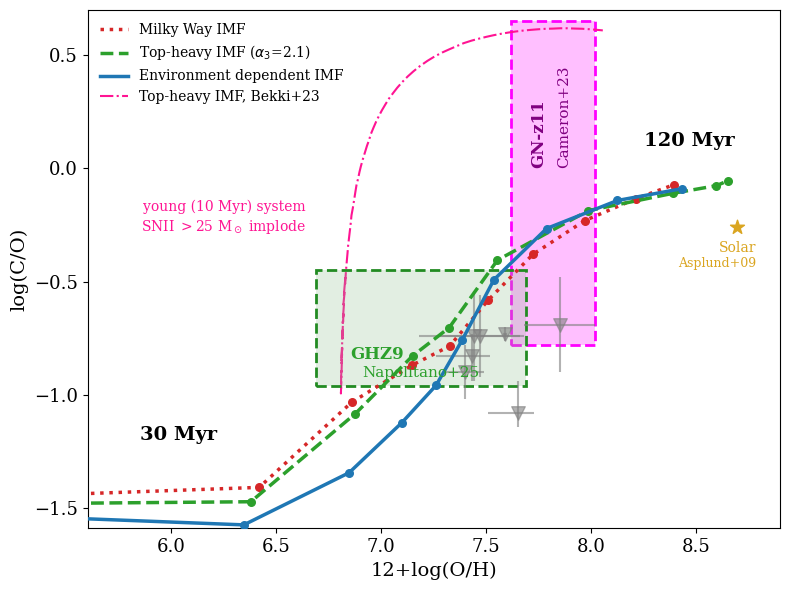

In [20]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import patches
from cmath import rect
from matplotlib.colors import ListedColormap

import os
%matplotlib inline

def load_file_paths(base_dir):
    file_paths = []
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file == "chemical_and_SN_evolution.txt":
                file_paths.append(os.path.join(root, file))
    return file_paths

def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

def recalculate(logCO, logOH):
    logCO = [i - 0.26 for i in logCO]
    logOH = [i + 8.696 for i in logOH]
    return logCO, logOH

def plot_Bekki_comparison():
    path = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha115_carbon.txt"
    data = np.loadtxt(path, delimiter=',')
    OH = data[:, 0]
    CO = data[:, 1]
    plt.plot(OH, CO, color='deeppink', lw=1.5, label='Top-heavy IMF, Bekki+23', linestyle='-.', zorder=0)
    plt.text(6.25, -0.2, 'young (10 Myr) system', color='deeppink', ha='center', va='bottom', fontsize=10)
    plt.text(6.25, -0.3, 'SNII $>$25 M$_\\odot~$implode', color='deeppink', ha='center', va='bottom', fontsize=10)

def plot_Cameron_carbon():
    xmin, xmax = 7.62, 8.02
    ymin, ymax = -0.78, 0.65
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, facecolor='magenta',
                         alpha=0.25, zorder=0)
    plt.gca().add_patch(rect)
    rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, edgecolor='magenta', facecolor='none',
                         alpha=1, linestyle='--', zorder=0)
    plt.gca().add_patch(rect1)
    # plt.plot([7.82, 7.92], [-0.25, 0.25], color='purple', linestyle=':', linewidth=2, marker=None)
    plt.text(7.75, 0, 'GN-z11', color='purple', ha='center', va='bottom', fontsize=12, rotation=90, weight="bold")
    plt.text(7.87, 0, 'Cameron+23', color='purple', ha='center', va='bottom', fontsize=11, rotation=90)

def plot_high_redshift_data_Ji25():
    # Define data points: (12+O/H, C/O, label, color, err_x, err_y, z)
    CB_color_cycle = ['#377eb8', '#ff7f00', '#4daf4a',
                  '#f781bf', '#a65628', '#984ea3',
                  '#999999', '#e41a1c', '#dede00']
    points = [
        # (8.38, -, 'Mrk 996 (high density)', cmap(0), 0.075, 0.28),
        # (8.36, -0.22, 'Mrk 996 (low density)', 0.225, 0.25, 0.00544),
        # (8.03, -0.51, 'LyC (high density)', 0.06, 0.05, 2.37),
        # # (8.00, -, 'ID150880', cmap(4), 0.10, 0.15),
        # ((7.15+7.67)/2, -0.06, 'UNCOvER-45924', 7.67-((7.15+7.67)/2), 0.055, 4.4655),
        # # (8.26, -, 'ID1665', cmap(6), 0.15, 0.15),
        # # (7.92, -, 'ID1746', cmap(7), 0.13, 0.15),
        # # (7.72, -, 'ID1477', cmap(8), 0.09, 0.11),
        # # (7.75, -, 'ID60001', cmap(9), 0.03, 0.03),
        # (7.97, -1.02, 'EXCELS-121806', 0.045, 0.22, 5.225),
        # (8, -0.38, 'GS_3073 (high density)', 0.115, 0.12, 5.55),
        (7.59, -0.73, 'GS_9422 (tentative)', CB_color_cycle[1], [[0.01], [0.01]] , [[0.03], [0.03]]),
        # # (7.96, -0.67, 'ID397', cmap(14), 0.10, 0.14),
        (7.43, -0.83, 'RXJ2248-ID', CB_color_cycle[1], [[0.17], [0.09]] , [[0.11], [0.10]]),
        (7.65, -1.08, 'GLASS_150008', CB_color_cycle[5], [[0.14], [0.08]] , [[0.06], [0.14]]),
        (7.47, -0.74, 'A1703-zdk6', CB_color_cycle[6], [[0.19], [0.19]], [[0.18], [0.18]]),
        (7.85, -0.69, 'GN-z8-LAE', CB_color_cycle[7], [[0.17], [0.17]], [[0.21], [0.21]]),
        # (8.37, -0.36, 'CEERS_01019 (AGN)', 0.135, 0, 8.679),
        # (7.94, -1.04, 'CEERS_01019 (SF)', 0.385, 0, 8.679),
        # (7.38, -1.18, 'GN-z9p4', CB_color_cycle[3], 0.15, 0, 9.380),
        # (7.49, -0.9, 'GS-z9-0 light-weighted', 0.13, 0.26, 9.4327),
        (7.4, -0.9, 'GS-z9-0', CB_color_cycle[2], [[0.09], [0.09]], [[0.12], [0.12]]),
        (7.44, -0.74, 'GHZ2/GLASS-z12', CB_color_cycle[8], [[0.26], [0.24]], [[0.2],[0.2]])
    ]

    xmin, xmax = 6.69, 7.69
    ymin, ymax = -0.96, -0.45
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, facecolor='darkseagreen',
                         alpha=0.25, zorder=5)
    plt.gca().add_patch(rect)
    rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, edgecolor='forestgreen', facecolor='none',
                         alpha=1, linestyle='--', zorder=5)
    plt.gca().add_patch(rect1)
    # plt.plot([7.82, 7.92], [-0.25, 0.25], color='purple', linestyle=':', linewidth=2, marker=None)
    plt.text(6.98, -0.86, 'GHZ9', color='tab:green', ha='center', va='bottom', fontsize=12, weight="bold", zorder=10)
    plt.text(7.19, -0.935, 'Napolitano+25', color='tab:green', ha='center', va='bottom', fontsize=11, zorder=10)
    plt.scatter(8.696, -0.26, color='goldenrod', s=110, marker='*')
    plt.text(8.696, -0.38, 'Solar', color='goldenrod', ha='center', va='bottom', fontsize=10)
    plt.text(8.6, -0.45, 'Asplund+09', color='goldenrod', ha='center', va='bottom', fontsize=9)
    handles = []
    for x, y, label, color, xerr, yerr in points:
        sc = plt.scatter(x, y, color='gray', s=95, marker='v', zorder=5, alpha=0.6)
        plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', elinewidth=1.5, ecolor='gray', zorder=5, alpha=0.6)
        handles.append(sc)


colours = colors = plt.get_cmap('tab10').colors  # Extend if needed
plt.rc('font', family='serif')
plt.figure(figsize=(8, 6))

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/canonical/imfKroupaSTF0.04alpha2.3Log_SFR0.2SFEN100SFE0.0068Z_0-4.15infall0.002/chemical_and_SN_evolution.txt")
file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/canonical/imfKroupaSTF0.04alpha2.3Log_SFR0.2SFEN100SFE0.0068Z_0-4.15infall0.002/chemical_and_SN_evolution.txt")
index_x = 1
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:red', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:red', lw=2.5, label='Milky Way IMF', linestyle="dotted", zorder=10)

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.006outf130/chemical_and_SN_evolution.txt")
index_x = 1
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=2.1)', linestyle="--", zorder=10)

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# index_x=1
# index_y=14

# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
#     time_steps = data['time step list:']
#     stellar_ages = np.log10(time_steps)
#     logCO, logOH = recalculate(logCO, logOH)
#     plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='black', s=30)
#     plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='black', lw=2.5, label='Bottom-heavy IMF (a1=1.8)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF0.04Log_SFR0.3SFEN100SFE0.008Z_0-4.15infall0.0065/chemical_and_SN_evolution.txt")
index_x = 0
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:blue', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:blue', lw=2.5, label='Environment dependent IMF', zorder=10)

plt.text(5.85, -1.2, '30 Myr', color='black', fontsize=14, weight="bold")    
plt.text(8.25, 0.1, '120 Myr', color='black', fontsize=14, weight="bold")

# plt.text(7.95, -1.4, 'Nomoto+13', color='tab:blue', ha='center', va='bottom', fontsize=17, weight="bold") 

filename='./paper/paper_carbon_can_th.pdf'
plt.xlabel('12+log(O/H)', fontsize=14)
plt.ylabel('log(C/O)', fontsize=14)
plt.locator_params(axis='x', nbins=8)
plt.locator_params(axis='y', nbins=8)
plt.xlim(5.6, 8.9)
plt.ylim(-1.59, 0.7)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
# plt.title(title, fontsize=12)
plot_Cameron_carbon()
plot_Bekki_comparison()
plot_high_redshift_data_Ji25()
plt.legend(bbox_to_anchor=(0, 1), loc="upper left", fontsize=10, frameon=False)
plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

In [70]:
def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

lifetime = load_data_with_names("/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_lifetime_from_Nomoto_sup_agb/Nomoto_sup_agb_Z=0.0001.txt")
mass = lifetime["mass"]
lifetime = lifetime["lifetime"]

for i in range (29):
    print(lifetime[i]/1e6, np.log10(mass[i]))


5669.999999999986 -1.0969100130080565
5669.999999999986 0.0
2840.9999999999927 0.09691001300805642
1660.999999999992 0.17609125905568124
1075.0000000000011 0.24303804868629444
858.6999999999965 0.2787536009528289
681.899999999999 0.3222192947339193
549.2999999999988 0.3521825181113625
420.1999999999992 0.3979400086720376
269.1999999999996 0.47712125471966244
188.20000000000005 0.5440680443502757
139.8999999999997 0.6020599913279624
108.80000000000014 0.6532125137753437
87.58999999999976 0.6989700043360189
72.45999999999972 0.7403626894942439
61.269999999999975 0.7781512503836436
55.07454375471051 0.8129133566428556
49.50555524383097 0.8450980400142568
44.49968774894079 0.8750612633917001
39.99999999999993 0.9030899869919435
36.754093900536155 0.9294189257142927
33.77158546123586 0.9542425094393249
17.159999999999958 1.1139433523068367
14.119999999999996 1.1760912590556813
11.250000000000004 1.255272505103306
9.975999999999967 1.3010299956639813
7.920999999999984 1.3979400086720377
6.55

Yields

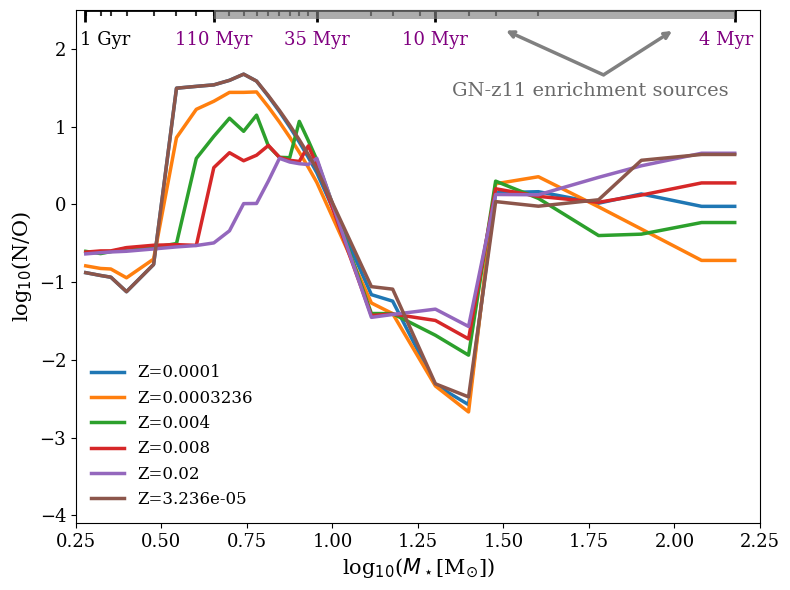

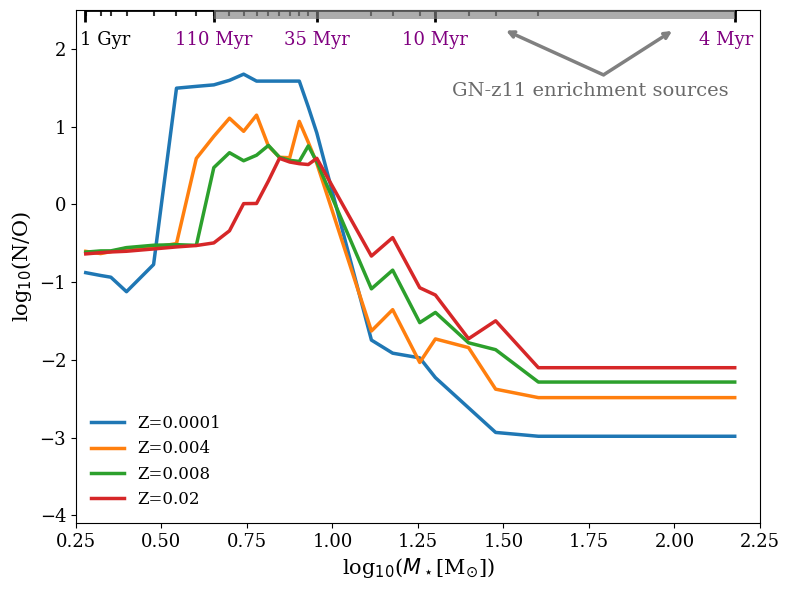

In [19]:
def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

def plot_NO_yields(file_paths_N, file_paths_O, filename):
    plt.figure(figsize=(8, 6))
    # Sort both lists to ensure matching order
    file_paths_N.sort()
    file_paths_O.sort()
    plt.rc('font', family='serif')
    for path_N, path_O in zip(file_paths_N, file_paths_O):
        data_N = load_data_with_names(path_N)
        data_O = load_data_with_names(path_O)
        mass = np.array(data_N['mass'])
        N_eject_mass = np.array(data_N['N_eject_mass'])
        O_eject_mass = np.array(data_O['O_eject_mass'])
        # Try to get metallicity from the data, otherwise use filename
        label = data_N.get('metallicity', [None])[0]
        if label is None:
            label = os.path.basename(path_N)
        with np.errstate(divide='ignore', invalid='ignore'):
            NO_ratio = np.where(O_eject_mass > 0, N_eject_mass / O_eject_mass, np.nan)
            plt.plot(np.log10(mass[5:]), np.log10(NO_ratio[5:]), label=f'Z={label}', lw=2.5)
    xmin, xmax = 0.28, 2.176
    yline = 2.5

    # Horizontal line
    plt.plot([xmin, xmax], [yline, yline],
            color='black', linewidth=2, zorder=6)

    # Tick positions
    tick_x = [0.278, 0.6532125137753437, 0.9542425094393249, 1.3010299956639813, 2.176]
    tick_height = 0.3

    # Ticks
    for x in tick_x:
        plt.vlines(x,
                yline - tick_height/2,
                yline + tick_height/2,
                color='black',
                linewidth=2,
                zorder=7)
    lifetime = load_data_with_names("/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_lifetime_from_Nomoto_sup_agb/Nomoto_sup_agb_Z=0.0001.txt")
    mass = lifetime["mass"]

    tick_height = 0.15

    # Ticks
    for x in np.log10(mass):
        plt.vlines(x,
                yline - tick_height/2,
                yline + tick_height/2,
                color='black',
                linewidth=1.5,
                alpha=0.8,
                zorder=7)

    # Age labels
    ages = ['', '110 Myr', '35 Myr', '10 Myr', '']
    plt.text(0.335, yline - 0.5, "1 Gyr", ha='center', va='bottom', fontsize=13, color='black', zorder=8)
    plt.text(2.15, yline - 0.5, "4 Myr", ha='center', va='bottom', fontsize=13, color='purple', zorder=8)

    plt.annotate('', xy=(1.5, 2.25), xytext=(1.8, 1.65), arrowprops=dict(facecolor='grey',ec = 'grey', arrowstyle='->', lw=2.5))
    plt.annotate('', xy=(2, 2.25), xytext=(1.787, 1.65), arrowprops=dict(facecolor='grey',ec = 'grey', arrowstyle='->', lw=2.5))
    plt.text(1.35, 1.4, "GN-z11 enrichment sources", fontsize=14, color='dimgrey', zorder=8)
    for x, age in zip(tick_x, ages):
        plt.text(x, yline - 0.5, age,
                ha='center',
                va='bottom',
                fontsize=13,
                color='purple',
                zorder=8)
    xmin, xmax = 0.6532125137753437, 2.176
    ymin, ymax = 2.38, 2.5
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                                 linewidth=2, facecolor='gray',
                                 alpha=0.65, zorder=10)
    plt.gca().add_patch(rect)
    # rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
    #                              linewidth=2, edgecolor='forestgreen', facecolor='none',
    #                              alpha=1, linestyle='--', zorder=5)
    # plt.gca().add_patch(rect1)
    plt.xlabel("log$_{10}$($M_\\star$[M$_{\\odot}$])", fontsize=15, fontname='serif')
    plt.ylabel('log$_{10}$(N/O)', fontsize=15)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.xlim(0.25, 2.25)
    plt.ylim(-4.1, 2.5)
    plt.legend(fontsize=12, loc='lower left', frameon=False)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

file_paths_N = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_N_eject_mass_from_Limongi_R300_sup_agb/*.txt')
file_paths_O = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_O_eject_mass_from_Limongi_R300_sup_agb/*.txt')
plot_NO_yields(file_paths_N, file_paths_O, filename='/Users/adriana_work/Desktop/galIMF/plotting/paper/NO_yields_Limongi_R300_sup_agb.pdf')

file_paths_N = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_N_eject_mass_from_Nomoto_sup_agb/*.txt')
file_paths_O = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_O_eject_mass_from_Nomoto_sup_agb/*.txt')
plot_NO_yields(file_paths_N, file_paths_O, filename='/Users/adriana_work/Desktop/galIMF/plotting/paper/NO_yields_Nomoto_sup_agb.pdf')


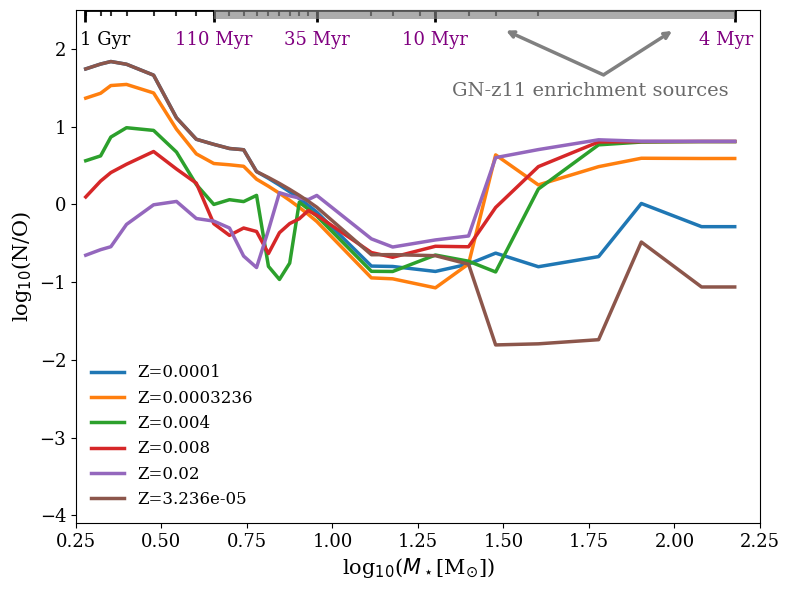

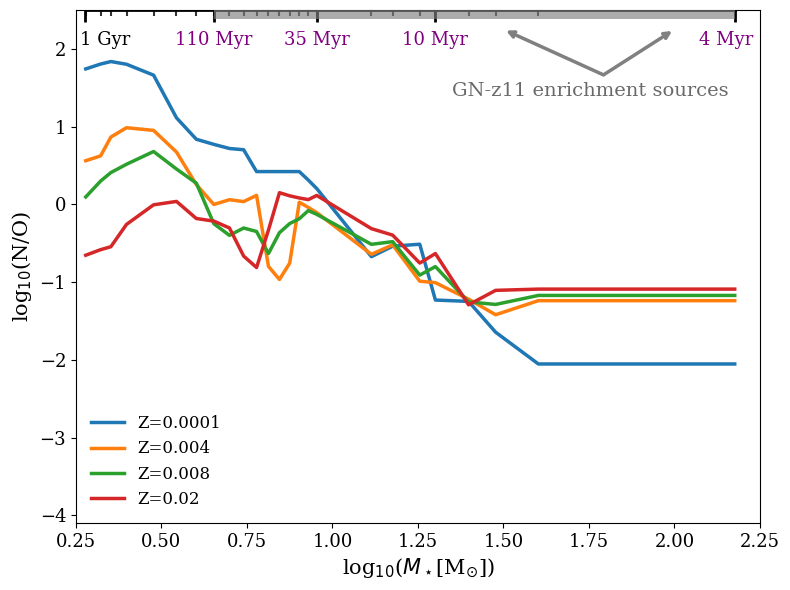

In [20]:
def plot_CO_yields(file_paths_C, file_paths_O, title, filename):
    plt.figure(figsize=(8, 6))
    # Sort both lists to ensure matching order
    file_paths_C.sort()
    file_paths_O.sort()
    plt.rc('font', family='serif')
    for path_C, path_O in zip(file_paths_C, file_paths_O):
        data_C = load_data_with_names(path_C)
        data_O = load_data_with_names(path_O)
        mass = np.array(data_C['mass'])
        C_eject_mass = np.array(data_C['C_eject_mass'])
        O_eject_mass = np.array(data_O['O_eject_mass'])
        # Try to get metallicity from the data, otherwise use filename
        label = data_C.get('metallicity', [None])[0]
        if label is None:
            label = os.path.basename(path_C)
        with np.errstate(divide='ignore', invalid='ignore'):
            CO_ratio = np.where(O_eject_mass > 0, C_eject_mass / O_eject_mass, np.nan)
            plt.plot(np.log10(mass[5:]), np.log10(CO_ratio[5:]), label=f'Z={label}', lw=2.5)
    xmin, xmax = 0.28, 2.176
    yline = 2.5

    # Horizontal line
    plt.plot([xmin, xmax], [yline, yline],
            color='black', linewidth=2, zorder=6)

    # Tick positions
    tick_x = [0.278, 0.6532125137753437, 0.9542425094393249, 1.3010299956639813, 2.176]
    tick_height = 0.3

    # Ticks
    for x in tick_x:
        plt.vlines(x,
                yline - tick_height/2,
                yline + tick_height/2,
                color='black',
                linewidth=2,
                zorder=7)
    lifetime = load_data_with_names("/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_lifetime_from_Nomoto_sup_agb/Nomoto_sup_agb_Z=0.0001.txt")
    mass = lifetime["mass"]

    tick_height = 0.15

    # Ticks
    for x in np.log10(mass):
        plt.vlines(x,
                yline - tick_height/2,
                yline + tick_height/2,
                color='black',
                linewidth=1.5,
                alpha=0.8,
                zorder=7)

    # Age labels
    ages = ['', '110 Myr', '35 Myr', '10 Myr', '']
    plt.text(0.335, yline - 0.5, "1 Gyr", ha='center', va='bottom', fontsize=13, color='black', zorder=8)
    plt.text(2.15, yline - 0.5, "4 Myr", ha='center', va='bottom', fontsize=13, color='purple', zorder=8)

    plt.annotate('', xy=(1.5, 2.25), xytext=(1.8, 1.65), arrowprops=dict(facecolor='grey',ec = 'grey', arrowstyle='->', lw=2.5))
    plt.annotate('', xy=(2, 2.25), xytext=(1.787, 1.65), arrowprops=dict(facecolor='grey',ec = 'grey', arrowstyle='->', lw=2.5))
    plt.text(1.35, 1.4, "GN-z11 enrichment sources", fontsize=14, color='dimgrey', zorder=8)
    for x, age in zip(tick_x, ages):
        plt.text(x, yline - 0.5, age,
                ha='center',
                va='bottom',
                fontsize=13,
                color='purple',
                zorder=8)
    xmin, xmax = 0.6532125137753437, 2.176
    ymin, ymax = 2.38, 2.5
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                                 linewidth=2, facecolor='gray',
                                 alpha=0.65, zorder=10)
    plt.gca().add_patch(rect)
    # rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
    #                              linewidth=2, edgecolor='forestgreen', facecolor='none',
    #                              alpha=1, linestyle='--', zorder=5)
    # plt.gca().add_patch(rect1)
    plt.xlabel("log$_{10}$($M_\\star$[M$_{\\odot}$])", fontsize=15, fontname='serif')
    plt.ylabel('log$_{10}$(N/O)', fontsize=15)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.xlim(0.25, 2.25)
    plt.ylim(-4.1, 2.5)
    plt.legend(fontsize=12, loc='lower left', frameon=False)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

file_paths_C = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_C_eject_mass_from_Limongi_R300_sup_agb/*.txt')
file_paths_O = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_O_eject_mass_from_Limongi_R300_sup_agb/*.txt')
plot_CO_yields(file_paths_C, file_paths_O, title='C/O Yield Composite of K10, D14 and LC18 R300', filename='/Users/adriana_work/Desktop/galIMF/plotting/paper/CO_yields_Limongi_R300_sup_agb.pdf')

file_paths_C = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_C_eject_mass_from_Nomoto_sup_agb/*.txt')
file_paths_O = glob.glob('/Users/adriana_work/Desktop/galIMF/yield_tables__2024/rearranged___/setllar_O_eject_mass_from_Nomoto_sup_agb/*.txt')
plot_CO_yields(file_paths_C, file_paths_O, title='C/O Yield Composite of K10, D14 and N13 without HNe', filename='/Users/adriana_work/Desktop/galIMF/plotting/paper/CO_yields_Nomoto_sup_agb.pdf')

Star formation history

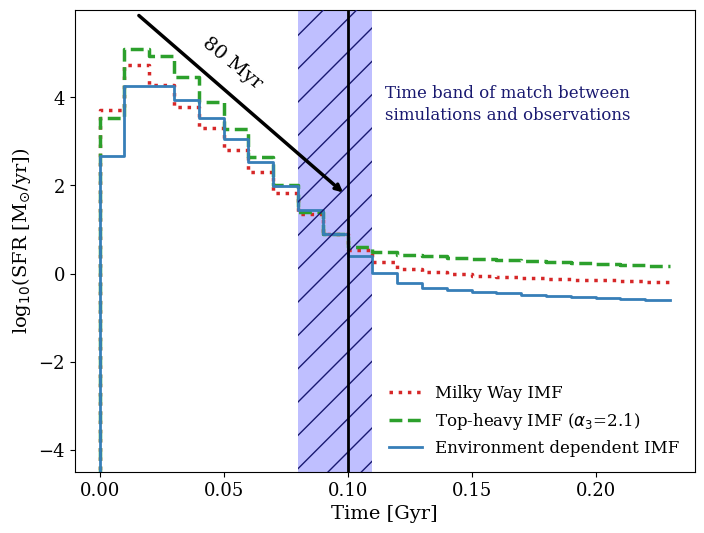

In [236]:
from scipy.integrate import quad
import glob
import numpy as np
import matplotlib.pyplot as plt
import os

def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

# def normalise(sfr_raw):
#     time = 1e8
#     M_raw = 10**(sfr_raw) * time
#     M_target = 10**8.9  # in M_sun
#     norm = M_target / M_raw
#     sfr_normalised = sfr_raw * norm  # units: M_sun/yr

#     return sfr_normalised

def normalise(age_gyr, log_sfr):
    idx_100 = np.argmin(np.abs(age_gyr - 0.1))
    offset = 0.9 - log_sfr[idx_100]
    log_sfr_norm = np.where(log_sfr <= -10, -22.0, log_sfr + offset)
    return log_sfr_norm

plt.figure(figsize=(8, 6))
plt.rc('font', family='serif')
colours = colors = plt.get_cmap('tab10').colors

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/canonical/imfKroupaSTF-4.15alpha2.3log_SFR<module 'IMFs.Kroupa_IMF' from '/Users/adriana_work/Desktop/galIMF/IMFs/Kroupa_IMF.py'>SFEN0.2SFE0.0068Z_0100infall0.002/plots/SFH.txt")
min = 0
max = 50
for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    age_list, sfr = data['age_list'], data['SFR_list']
    age_list = np.array(age_list, dtype=float) - 0.01
    sfr = np.array(sfr)
    sfr_norm = normalise(age_list, sfr)
    plt.plot(age_list[min:max], sfr_norm[min:max], color='tab:red', lw=2.5, label='Milky Way IMF', linestyle="dotted")

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha1.6Log_SFR0.3SFEN0.008SFE100infall0.0065outf110/plots/SFH.txt")
# min = 0
# max = 45
# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     age_list, sfr = data['age_list'], data['SFR_list']
#     age_list = np.array(age_list, dtype=float) - 0.01
#     plt.plot(age_list[min:max], sfr[min:max], color='#377eb8', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=1.6)', linestyle="--")

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha1.8Log_SFR0.3SFEN0.008SFE100infall0.0065outf110/plots/SFH.txt")
# min = 0
# max = 45
# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     age_list, sfr = data['age_list'], data['SFR_list']
#     age_list = np.array(age_list, dtype=float) - 0.01
#     plt.plot(age_list[min:max], sfr[min:max], color='#ff7f00', lw=3, label='Top-heavy IMF ($\\alpha_3$=1.8)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN0.008SFE100infall0.006outf130/plots/SFH.txt")
min = 0
max = 50
for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    age_list, sfr = data['age_list'], data['SFR_list']
    age_list = np.array(age_list, dtype=float) - 0.01
    sfr = np.array(sfr)
    sfr_norm = normalise(age_list, sfr)
    plt.plot(age_list[min:max], sfr_norm[min:max], color='tab:green', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=2.1)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF-4.15alpha2.3log_SFR<module 'igimf_SFR_-416853_Fe_over_H_-702629' from '/Users/adriana_work/Desktop/galIMF/Generated_IGIMFs/igimf_SFR_-416853_Fe_over_H_-702629.py'>SFEN0.3SFE0.008Z_0100infall0.0065/plots/SFH.txt")
# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfLog_SFR0.3SFEN0.008SFE100infall0.009outf100/plots/SFH.txt")
min = 0
max = 50
for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    age_list, sfr = data['age_list'], data['SFR_list']
    age_list = np.array(age_list, dtype=float) - 0.01
    sfr = np.array(sfr)
    sfr_norm = normalise(age_list, sfr)
    plt.plot(age_list[min:max], sfr_norm[min:max], color='#377eb8', lw=2, label='Environment dependent IMF')

plt.plot([0.1, 0.1], [-7, 7], color='black', linewidth=2, zorder=6)
plt.annotate('', xy=(0.099, 1.8), xytext=(0.015, 5.9), arrowprops=dict(facecolor='black',ec = 'black', arrowstyle='->', lw=2.5), zorder=10)
plt.text(0.04, 4.2, "80 Myr", fontsize=14, color='black', zorder=8, rotation=-39)

xmin, xmax = 0.08, 0.11
ymin, ymax = -4.6, 8
rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, facecolor='blue',
                         alpha=0.25, zorder=0)
plt.gca().add_patch(rect)
rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, edgecolor='midnightblue', facecolor='none',
                         alpha=1, linestyle=' ', zorder=5, hatch='/')
plt.gca().add_patch(rect1)
plt.text(0.115, 4, "Time band of match between", fontsize=12, color='midnightblue', zorder=8)
plt.text(0.115, 3.5, "simulations and observations", fontsize=12, color='midnightblue', zorder=8)

plt.xlabel('Time [Gyr]', fontsize=14)
plt.ylabel('log$_{10}$(SFR [M$_{\\odot}$/yr])', fontsize=14)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.locator_params(axis='x', nbins=8)
plt.ylim(-4.5,5.99)
plt.xlim(-0.01, 0.24)
plt.legend(loc='lower right', fontsize=12, frameon=False)
plt.savefig('/Users/adriana_work/Desktop/galIMF/plotting/paper/sfh.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [162]:
print("VALUE THAT WE WANT", 14.7)
print("VALUE THAT WE HAVE AND IS WRONG", 10**(0.8999999999999999))


VALUE THAT WE WANT 14.7
VALUE THAT WE HAVE AND IS WRONG 7.943282347242813


Imf effect

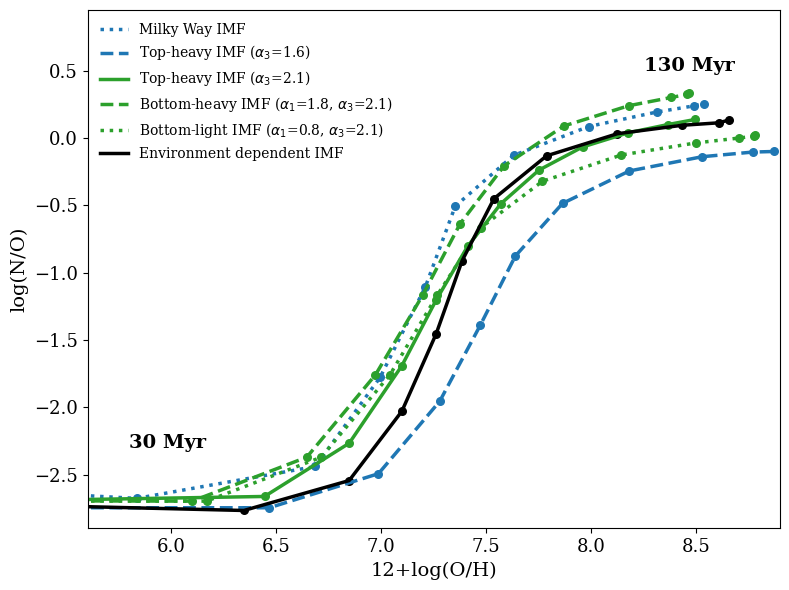

In [11]:
def load_file_paths(base_dir):
    file_paths = []
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file == "chemical_and_SN_evolution.txt":
                file_paths.append(os.path.join(root, file))
    return file_paths

def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

def recalculate(logNO, logOH): # Recalculate logNO and logOH
    logNO = [i - 0.86 for i in logNO]
    logOH = [i + 8.696 for i in logOH]
    return logNO, logOH

def fit(logOH, logNO): # Fit a polynomial to the data
    coefficients = np.polyfit(logOH, logNO, deg=6)
    polynomial = np.poly1d(coefficients)
    smooth_logOH = np.linspace(min(logOH[6:]), max(logOH[6:]), 500)
    smooth_logNO = polynomial(smooth_logOH)
    return smooth_logOH, smooth_logNO

def prepare_data(file_paths):
    for path in file_paths:
        data = load_data_with_names(path)
        logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
        FeH, MgH, OH = data['Gas [Fe/H]:'], data['Gas [Mg/H]:'], data['Gas [O/H]:']
        timestep = data['time step list:']
        logNO_rec, logOH_rec = recalculate(logNO, logOH)
        smooth_logOH, smooth_logNO = fit(logOH_rec, logNO_rec)
    return smooth_logOH, smooth_logNO

plt.rc('font', family='serif')
plt.figure(figsize=(8, 6))

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.3Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x=2
index_y=13

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:blue', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:blue', lw=2.5, label='Milky Way IMF', linestyle="dotted")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha1.6Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x=1
index_y=13

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:blue', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:blue', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=1.6)', linestyle="--")

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha1.8Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# index_x=1
# index_y=13

# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
#     time_steps = data['time step list:']
#     stellar_ages = np.log10(time_steps)
#     logNO, logOH = recalculate(logNO, logOH)
#     plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:orange', s=30)
#     plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:orange', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=1.8)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/Nomoto_sup_agb/20260502/imfKroupaSTF0.04alpha2.1Log_SFR0.2SFEN100SFE0.0062Z_0-4.15infall0.002/chemical_and_SN_evolution.txt")
index_x=1
index_y=14

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=2.1)')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.1bottom-heavy_Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x=1
index_y=14

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', lw=2.5, label='Bottom-heavy IMF ($\\alpha_1$=1.8, $\\alpha_3$=2.1)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.1bottom-light_Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x=1
index_y=14

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='tab:green', lw=2.5, label='Bottom-light IMF ($\\alpha_1$=0.8, $\\alpha_3$=2.1)', linestyle=":")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF0.04Log_SFR0.3SFEN100SFE0.008Z_0-4.15infall0.0065/chemical_and_SN_evolution.txt")
index_x=1
index_y=14

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='black', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='black', lw=2.5, label='Environment dependent IMF')

plt.text(5.8, -2.3, '30 Myr', color='black', fontsize=14, weight="bold")    
plt.text(8.25, 0.5, '130 Myr', color='black', fontsize=14, weight="bold")       

filename='./paper/paper_nitrogen_dif_imf.pdf'
plt.xlabel('12+log(O/H)', fontsize=14)
plt.ylabel('log(N/O)', fontsize=14)
plt.xlim(5.6, 8.9)
plt.locator_params(axis='x', nbins=8)
plt.ylim(-2.9, 0.95)
plt.locator_params(axis='y', nbins=8)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.legend(bbox_to_anchor=(0, 1), loc="upper left", fontsize=10, frameon=False)
plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

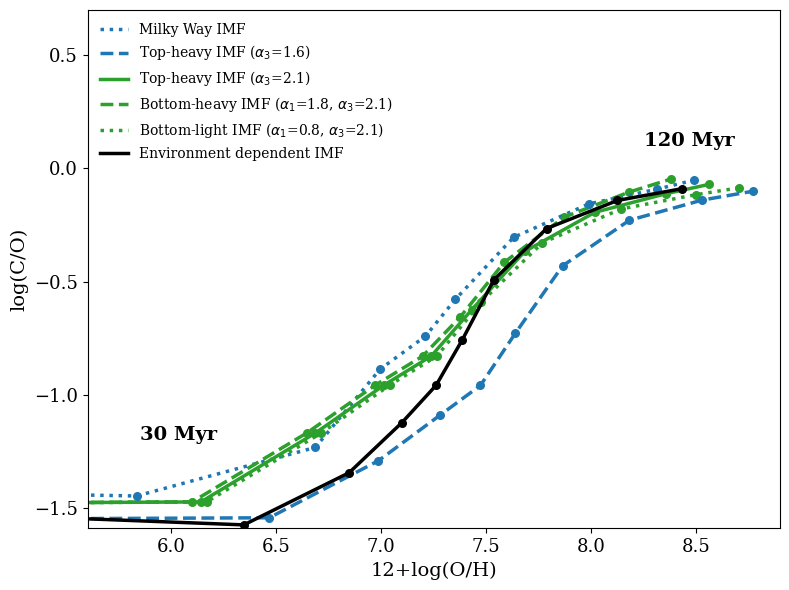

In [13]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import patches
from cmath import rect
from matplotlib.colors import ListedColormap

import os
%matplotlib inline

def load_file_paths(base_dir):
    file_paths = []
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file == "chemical_and_SN_evolution.txt":
                file_paths.append(os.path.join(root, file))
    return file_paths

def load_data_with_names(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()
    data_dict = {}
    for i in range(len(lines)):
        line = lines[i].strip()
        if line.startswith("#"):
            row_name = line[1:].strip()
            if i + 1 < len(lines):
                data = list(map(float, lines[i + 1].strip().split()))
                data_dict[row_name] = data
    return data_dict

def recalculate(logCO, logOH):
    logCO = [i - 0.26 for i in logCO]
    logOH = [i + 8.696 for i in logOH]
    return logCO, logOH

colours = colors = plt.get_cmap('tab10').colors  # Extend if needed
plt.rc('font', family='serif')
plt.figure(figsize=(8, 6))

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/canonical/imfKroupaSTF0.04alpha2.3Log_SFR0.2SFEN100SFE0.0068Z_0-4.15infall0.002/chemical_and_SN_evolution.txt")
file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.3Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x = 1
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:blue', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:blue', lw=2.5, label='Milky Way IMF', linestyle="dotted")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha1.6Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x = 1
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:blue', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:blue', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=1.6)', linestyle="--")

# # file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaSTF0.04alpha1.8Log_SFR0.4SFEN100SFE0.006Z_0-4.15infall0.0085/chemical_and_SN_evolution.txt")
# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha1.8Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# index_x = 1
# index_y = 12

# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
#     time_steps = data['time step list:']
#     stellar_ages = np.log10(time_steps)
#     logCO, logOH = recalculate(logCO, logOH)
#     # smooth_logOH, smooth_logNO = fit(logOH, logNO)
#     # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
#     plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:orange', s=30, zorder=10)
#     plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:orange', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=1.8)', linestyle="--")

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/top_heavy/imfKroupaSTF0.04alpha1.8Log_SFR0.4SFEN100SFE0.006Z_0-4.15infall0.0085/chemical_and_SN_evolution.txt")
file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x = 1
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', lw=2.5, label='Top-heavy IMF ($\\alpha_3$=2.1)')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.1bottom-heavy_Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x=1
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', lw=2.5, label='Bottom-heavy IMF ($\\alpha_1$=1.8, $\\alpha_3$=2.1)', linestyle="--")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/imf_comparison/imfKroupaalpha2.1bottom-light_Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaalpha2.1Log_SFR0.3SFEN100SFE0.008infall0.0065outf110/chemical_and_SN_evolution.txt")
index_x=1
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='tab:green', lw=2.5, label='Bottom-light IMF ($\\alpha_1$=0.8, $\\alpha_3$=2.1)', linestyle=":")

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF0.04Log_SFR0.3SFEN100SFE0.008Z_0-4.15infall0.0065/chemical_and_SN_evolution.txt")
index_x = 0
index_y = 12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    # smooth_logOH, smooth_logNO = fit(logOH, logNO)
    # plt.plot(smooth_logOH[index_x:index_y], smooth_logNO[index_x:index_y], color=colors[i % len(colors)], lw=0.8, label=label)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='black', s=30, zorder=10)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='black', lw=2.5, label='Environment dependent IMF', zorder=10)

plt.text(5.85, -1.2, '30 Myr', color='black', fontsize=14, weight="bold")    
plt.text(8.25, 0.1, '120 Myr', color='black', fontsize=14, weight="bold")

# plt.text(7.95, -1.4, 'Nomoto+13', color='tab:blue', ha='center', va='bottom', fontsize=17, weight="bold") 

filename='./paper/paper_carbon_dif_imf.pdf'
plt.xlabel('12+log(O/H)', fontsize=14)
plt.ylabel('log(C/O)', fontsize=14)
plt.locator_params(axis='x', nbins=8)
plt.locator_params(axis='y', nbins=8)
plt.xlim(5.6, 8.9)
plt.ylim(-1.59, 0.7)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
# plt.title(title, fontsize=12)
plt.legend(bbox_to_anchor=(0, 1), loc="upper left", fontsize=10, frameon=False)
plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

All IGIMF variations plot

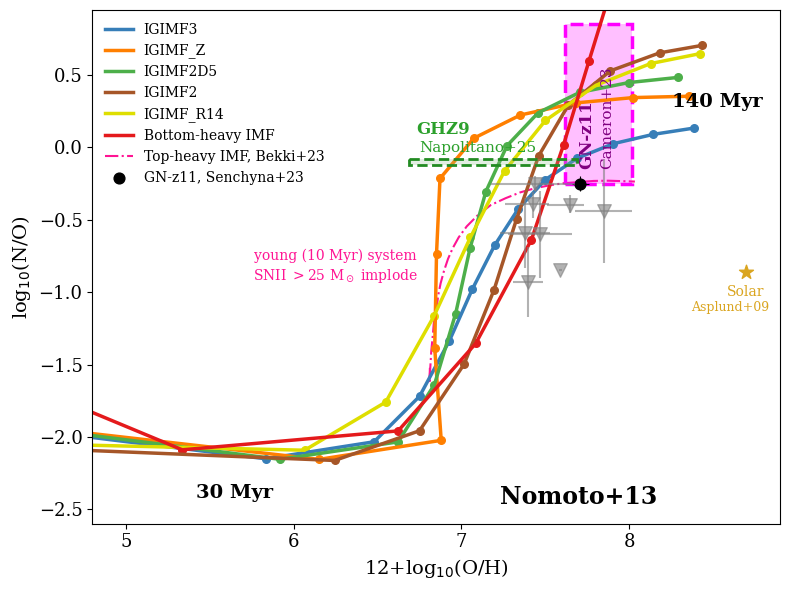

In [177]:
  # Extend if needed
def plot_Bekki_comparison():
    patha115 = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha115.csv"
    patha155 = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha155.csv"
    patha235 = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha235.csv"
    pathdwarf = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/dwarf.csv"

    a115 = np.loadtxt(patha115, delimiter=',')
    a155 = np.loadtxt(patha155, delimiter=',')
    a235 = np.loadtxt(patha235, delimiter=',')
    dwarf = np.loadtxt(pathdwarf, delimiter=',')

    BlogOHa115 = a115[:, 0]
    BlogNOa115 = a115[:, 1]
    BlogOHa155 = a155[:, 0]
    BlogNOa155 = a155[:, 1]
    BlogOHa235 = a235[:, 0]
    BlogNOa235 = a235[:, 1]
    BlogOHdwarf = dwarf[:, 0]
    BlogNOdwarf = dwarf[:, 1] 

    plt.rc('font', family='serif')
    # plt.plot(BlogOHa155, BlogNOa155, color='palevioletred', lw=1.1, label='Bekki, $\\alpha=1.55$', linestyle=':')
    plt.plot(BlogOHa115, BlogNOa115, color='deeppink', lw=1.5, label='Top-heavy IMF, Bekki+23', linestyle='-.', zorder=0)
    plt.text(6.25, -0.8, 'young (10 Myr) system', color='deeppink', ha='center', va='bottom', fontsize=10)
    plt.text(6.25, -0.95, 'SNII $>$25 M$_\odot~$implode', color='deeppink', ha='center', va='bottom', fontsize=10)
    # plt.plot(BlogOHa235, BlogNOa235, color='crimson', lw=1, label='Bekki, $\\alpha=2.35$', linestyle='--')
    # plt.plot(BlogOHdwarf, BlogNOdwarf, color='darkmagenta', lw=1, label='Bekki, dwarf', linestyle='-.')
    Xmin, Xmax = 6.69, 7.69
    Ymin, Ymax = -0.08, -0.12
    rect2 = patches.Rectangle((Xmin, Ymin), Xmax-Xmin, Ymax-Ymin,
                         linewidth=2, facecolor='darkseagreen',
                         alpha=0.25, zorder=10)
    plt.gca().add_patch(rect2)
    rect3 = patches.Rectangle((Xmin, Ymin), Xmax-Xmin, Ymax-Ymin,
                         linewidth=2, edgecolor='forestgreen', facecolor='none',
                         alpha=1, linestyle='--', zorder=10)
    plt.gca().add_patch(rect3)
    plt.text(6.89, 0.065, 'GHZ9', color='tab:green', ha='center', va='bottom', fontsize=12, weight="bold")
    plt.text(7.1, -0.05, 'Napolitano+25', color='tab:green', ha='center', va='bottom', fontsize=11)

    xmin, xmax = 7.62, 8.02
    ymin, ymax = -0.25, 0.85
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2.5, facecolor='magenta',
                         alpha=0.25, zorder=0)
    plt.gca().add_patch(rect)
    rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2.5, edgecolor='magenta', facecolor='none',
                         alpha=1, linestyle='--', zorder=0)
    plt.gca().add_patch(rect1)
    # plt.plot([7.82, 7.92], [-0.25, 0.25], color='purple', linestyle=':', linewidth=2, marker=None)
    plt.text(7.75, - 0.25 + 0.1, 'GN-z11', color='purple', ha='center', va='bottom', fontsize=12, rotation=90, weight="bold", zorder=10)
    plt.text(7.87, - 0.25 + 0.1, 'Cameron+23', color='purple', ha='center', va='bottom', fontsize=11, rotation=90, zorder=10)
    # plt.scatter(7.84, -0.38, color='black', label='GN-z11', s=30, marker='*') # from Senchyna23 https://arxiv.org/pdf/2303.04179 (gas + dust)
    plt.scatter(7.71, -0.25, color='black', label='GN-z11, Senchyna+23', s=60, marker='o', zorder=5) # gas-phase only (Senchyna23), BEAGLE line fitting
    plt.errorbar(7.71, -0.25, 0.05, 0.05, fmt='none', elinewidth=0.8, ecolor='black', zorder=5)
    plt.scatter(8.696, -0.86, color='goldenrod', s=110, marker='*')
    plt.text(8.696, -1.05, 'Solar', color='goldenrod', ha='center', va='bottom', fontsize=10)
    plt.text(8.6, -1.15, 'Asplund+09', color='goldenrod', ha='center', va='bottom', fontsize=9)
    # ax = plt.gca()
    # ax.axhline(-0.86, color='red', linestyle='--', linewidth=0.5, label='Solar')
    # ay = plt.gca()
    # ay.axvline(8.696, color='red', linestyle='--', linewidth=0.5)
    # plt.scatter(7.91, -0.2, color='red', label='GN-z11', s=30, marker='*')


plt.rc('font', family='serif')
plt.figure(figsize=(8, 6))

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf3/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.009/chemical_and_SN_evolution.txt")
index_x=0
index_y=15

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#377eb8', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#377eb8', lw=2.5, label='IGIMF3')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf_z/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.009/chemical_and_SN_evolution.txt")
index_x=0
index_y=13

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#ff7f00', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#ff7f00', lw=2.5, label='IGIMF_Z')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2d5/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.009/chemical_and_SN_evolution.txt")
index_x=0
index_y=14

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#4daf4a', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#4daf4a', lw=2.5, label='IGIMF2D5')

######

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.0065/chemical_and_SN_evolution.txt")
index_x=0
index_y=13

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#a65628', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#a65628', lw=2.5, label='IGIMF2')

# file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/Nomoto_sup_agb/20260502/imfKroupaSTF0.04alpha2.1Log_SFR0.2SFEN100SFE0.0062Z_0-4.15infall0.002/chemical_and_SN_evolution.txt")
# index_x=4
# index_y=14

# for i, path in enumerate(file_paths):
#     data = load_data_with_names(path)
#     logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
#     time_steps = data['time step list:']
#     stellar_ages = np.log10(time_steps)
#     logNO, logOH = recalculate(logNO, logOH)
#     plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#984ea3', s=30)
#     plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#984ea3', lw=2.5, label='Environment dependent IMF')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf_r14/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.006/chemical_and_SN_evolution.txt")
index_x=0
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#dede00', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#dede00', lw=2.5, label='IGIMF_R14')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaSTF0.04alpha1.8Log_SFR1.0SFEN15SFE*Z_0-4.15infall*/chemical_and_SN_evolution.txt")
index_x=0
index_y=10
for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logNO, logOH = data['Gas [N/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logNO, logOH = recalculate(logNO, logOH)
    plt.scatter(logOH[index_x:index_y], logNO[index_x:index_y], color='#e41a1c', s=30)
    plt.plot(logOH[index_x:index_y], logNO[index_x:index_y], color='#e41a1c', lw=2.5, label='Bottom-heavy IMF')


plt.text(5.65, -2.45, '30 Myr', color='black', ha='center', va='bottom', fontsize=14, weight="bold")    
plt.text(8.525, 0.25, '140 Myr', color='black', ha='center', va='bottom', fontsize=14, weight="bold")       

plt.text(7.7, -2.5, 'Nomoto+13', color='black', ha='center', va='bottom', fontsize=17, weight="bold") 
# plt.text(5.45, -1.75, 'LC18', color='tab:orange', ha='center', va='bottom', rotation=30, fontsize=17, weight="bold")

title='Chemical evolution models with different IMF slopes'
filename='./paper/igimf_variations_nitrogen.pdf'
plot_Bekki_comparison()
plt.xlabel('12+log$_{10}$(O/H)', fontsize=14)
plt.ylabel('log$_{10}$(N/O)', fontsize=14)
plt.xlim(4.8, 8.9)
plt.locator_params(axis='x', nbins=8)
plt.ylim(-2.6, 0.95)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.locator_params(axis='y', nbins=8)
plt.legend(bbox_to_anchor=(0, 1), loc="upper left", fontsize=10, frameon=False)
# lgd_obs = plot_high_redshift_gal_data()
# plt.gca().add_artist(lgd_obs)
plot_high_redshift_gal_data()
# plt.title(title, fontsize=16)
plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

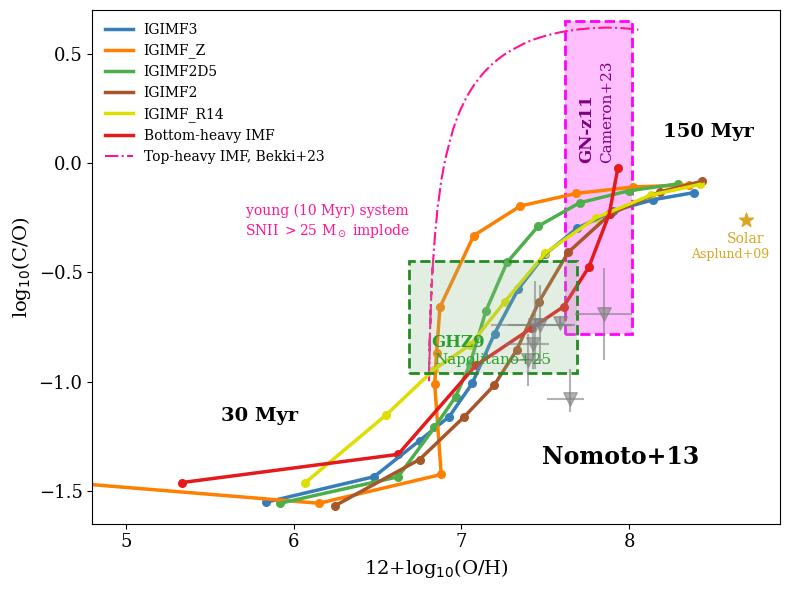

In [178]:
def recalculate(logCO, logOH):
    logCO = [i - 0.26 for i in logCO]
    logOH = [i + 8.696 for i in logOH]
    return logCO, logOH

def plot_Bekki_comparison():
    path = "/Users/adriana_work/Desktop/galIMF/Bekki paper stolen plots/alpha115_carbon.txt"
    data = np.loadtxt(path, delimiter=',')
    OH = data[:, 0]
    CO = data[:, 1]
    plt.plot(OH, CO, color='deeppink', lw=1.5, label='Top-heavy IMF, Bekki+23', linestyle='-.', zorder=0)
    plt.text(6.2, -0.25, 'young (10 Myr) system', color='deeppink', ha='center', va='bottom', fontsize=10)
    plt.text(6.2, -0.35, 'SNII $>$25 M$_\\odot~$implode', color='deeppink', ha='center', va='bottom', fontsize=10)

def plot_Cameron_carbon():
    xmin, xmax = 7.62, 8.02
    ymin, ymax = -0.78, 0.65
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, facecolor='magenta',
                         alpha=0.25, zorder=0)
    plt.gca().add_patch(rect)
    rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, edgecolor='magenta', facecolor='none',
                         alpha=1, linestyle='--', zorder=0)
    plt.gca().add_patch(rect1)
    # plt.plot([7.82, 7.92], [-0.25, 0.25], color='purple', linestyle=':', linewidth=2, marker=None)
    plt.text(7.75, 0, 'GN-z11', color='purple', ha='center', va='bottom', fontsize=12, rotation=90, weight="bold")
    plt.text(7.87, 0, 'Cameron+23', color='purple', ha='center', va='bottom', fontsize=11, rotation=90)

def plot_high_redshift_data_Ji25():
    # Define data points: (12+O/H, C/O, label, color, err_x, err_y, z)
    CB_color_cycle = ['#377eb8', '#ff7f00', '#4daf4a',
                  '#f781bf', '#a65628', '#984ea3',
                  '#999999', '#e41a1c', '#dede00']
    points = [
        # (8.38, -, 'Mrk 996 (high density)', cmap(0), 0.075, 0.28),
        # (8.36, -0.22, 'Mrk 996 (low density)', 0.225, 0.25, 0.00544),
        # (8.03, -0.51, 'LyC (high density)', 0.06, 0.05, 2.37),
        # # (8.00, -, 'ID150880', cmap(4), 0.10, 0.15),
        # ((7.15+7.67)/2, -0.06, 'UNCOvER-45924', 7.67-((7.15+7.67)/2), 0.055, 4.4655),
        # # (8.26, -, 'ID1665', cmap(6), 0.15, 0.15),
        # # (7.92, -, 'ID1746', cmap(7), 0.13, 0.15),
        # # (7.72, -, 'ID1477', cmap(8), 0.09, 0.11),
        # # (7.75, -, 'ID60001', cmap(9), 0.03, 0.03),
        # (7.97, -1.02, 'EXCELS-121806', 0.045, 0.22, 5.225),
        # (8, -0.38, 'GS_3073 (high density)', 0.115, 0.12, 5.55),
        (7.59, -0.73, 'GS_9422 (tentative)', CB_color_cycle[1], [[0.01], [0.01]] , [[0.03], [0.03]]),
        # # (7.96, -0.67, 'ID397', cmap(14), 0.10, 0.14),
        (7.43, -0.83, 'RXJ2248-ID', CB_color_cycle[1], [[0.17], [0.09]] , [[0.11], [0.10]]),
        (7.65, -1.08, 'GLASS_150008', CB_color_cycle[5], [[0.14], [0.08]] , [[0.06], [0.14]]),
        (7.47, -0.74, 'A1703-zdk6', CB_color_cycle[6], [[0.19], [0.19]], [[0.18], [0.18]]),
        (7.85, -0.69, 'GN-z8-LAE', CB_color_cycle[7], [[0.17], [0.17]], [[0.21], [0.21]]),
        # (8.37, -0.36, 'CEERS_01019 (AGN)', 0.135, 0, 8.679),
        # (7.94, -1.04, 'CEERS_01019 (SF)', 0.385, 0, 8.679),
        # (7.38, -1.18, 'GN-z9p4', CB_color_cycle[3], 0.15, 0, 9.380),
        # (7.49, -0.9, 'GS-z9-0 light-weighted', 0.13, 0.26, 9.4327),
        (7.4, -0.9, 'GS-z9-0', CB_color_cycle[2], [[0.09], [0.09]], [[0.12], [0.12]]),
        (7.44, -0.74, 'GHZ2/GLASS-z12', CB_color_cycle[8], [[0.26], [0.24]], [[0.2],[0.2]])
    ]

    xmin, xmax = 6.69, 7.69
    ymin, ymax = -0.96, -0.45
    rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, facecolor='darkseagreen',
                         alpha=0.25, zorder=5)
    plt.gca().add_patch(rect)
    rect1 = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                         linewidth=2, edgecolor='forestgreen', facecolor='none',
                         alpha=1, linestyle='--', zorder=5)
    plt.gca().add_patch(rect1)
    # plt.plot([7.82, 7.92], [-0.25, 0.25], color='purple', linestyle=':', linewidth=2, marker=None)
    plt.text(6.98, -0.86, 'GHZ9', color='tab:green', ha='center', va='bottom', fontsize=12, weight="bold", zorder=10)
    plt.text(7.19, -0.935, 'Napolitano+25', color='tab:green', ha='center', va='bottom', fontsize=11, zorder=10)
    plt.scatter(8.696, -0.26, color='goldenrod', s=110, marker='*')
    plt.text(8.696, -0.38, 'Solar', color='goldenrod', ha='center', va='bottom', fontsize=10)
    plt.text(8.6, -0.45, 'Asplund+09', color='goldenrod', ha='center', va='bottom', fontsize=9)
    handles = []
    for x, y, label, color, xerr, yerr in points:
        sc = plt.scatter(x, y, color='gray', s=95, marker='v', zorder=5, alpha=0.6)
        plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', elinewidth=1.5, ecolor='gray', zorder=5, alpha=0.6)
        handles.append(sc)


plt.rc('font', family='serif')
plt.figure(figsize=(8, 6))

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf3/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.009/chemical_and_SN_evolution.txt")
index_x=3
index_y=15

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='#377eb8', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='#377eb8', lw=2.5, label='IGIMF3')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf_z/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.009/chemical_and_SN_evolution.txt")
index_x=0
index_y=13

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='#ff7f00', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='#ff7f00', lw=2.5, label='IGIMF_Z')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2d5/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.009/chemical_and_SN_evolution.txt")
index_x=3
index_y=14

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='#4daf4a', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='#4daf4a', lw=2.5, label='IGIMF2D5')

######

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf2/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.0065/chemical_and_SN_evolution.txt")
index_x=3
index_y=13

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='#a65628', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='#a65628', lw=2.5, label='IGIMF2')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/igimf_r14/imfigimfSTF0.04Log_SFR1.0SFEN15SFE0.008Z_0-4.15infall0.006/chemical_and_SN_evolution.txt")
index_x=3
index_y=12

for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='#dede00', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='#dede00', lw=2.5, label='IGIMF_R14')

file_paths = glob.glob("/Users/adriana_work/Desktop/galIMF/simulation_results_from_galaxy_evol/paper/nomoto/bottom_heavy/imfKroupaSTF0.04alpha1.8Log_SFR1.0SFEN15SFE*Z_0-4.15infall*/chemical_and_SN_evolution.txt")
index_x=2
index_y=10
for i, path in enumerate(file_paths):
    data = load_data_with_names(path)
    logCO, logOH = data['Gas [C/O]:'], data['Gas [O/H]:']
    time_steps = data['time step list:']
    stellar_ages = np.log10(time_steps)
    logCO, logOH = recalculate(logCO, logOH)
    plt.scatter(logOH[index_x:index_y], logCO[index_x:index_y], color='#e41a1c', s=30)
    plt.plot(logOH[index_x:index_y], logCO[index_x:index_y], color='#e41a1c', lw=2.5, label='Bottom-heavy IMF')


plt.text(5.8, -1.2, '30 Myr', color='black', ha='center', va='bottom', fontsize=14, weight="bold")    
plt.text(8.475, 0.1, '150 Myr', color='black', ha='center', va='bottom', fontsize=14, weight="bold")

plt.text(7.95, -1.4, 'Nomoto+13', color='black', ha='center', va='bottom', fontsize=17, weight="bold") 
# plt.text(5.45, -1.75, 'LC18', color='tab:orange', ha='center', va='bottom', rotation=30, fontsize=17, weight="bold")

filename='./paper/igimf_variations_carbon.pdf'
plt.xlabel('12+log$_{10}$(O/H)', fontsize=14)
plt.ylabel('log$_{10}$(C/O)', fontsize=14)
plt.locator_params(axis='x', nbins=8)
plt.locator_params(axis='y', nbins=8)
plt.xlim(4.8, 8.9)
plt.ylim(-1.65, 0.7)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
# plt.title(title, fontsize=12)
plot_Cameron_carbon()
plot_Bekki_comparison()
plot_high_redshift_data_Ji25()
plt.legend(bbox_to_anchor=(0, 1), loc="upper left", fontsize=10, frameon=False)
plt.savefig(filename, bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()